# 🎬 OTT Content Strategy & Audience Insights
### End-to-End Data Cleaning, Exploratory Analysis, SQL Modeling & Content Segmentation
**Author:** Ranjith Kumar  
**Tools Used:** Python (Pandas, NumPy, Matplotlib, Seaborn) • SQL (DuckDB) • Streamlit

---

### Project Overview
In this notebook, I walk through the full analytics lifecycle for an OTT streaming platform catalog (8,800+ titles). As streaming services face intensifying competition and rising production costs, understanding catalog composition, viewer sentiment, and category efficiency is essential for content licensing and commissioning decisions.

**Key Questions Addressed:**
1. How has our catalog expanded over time, and how has the balance between movies and episodic series shifted?
2. Which genres and languages drive the majority of catalog volume versus high audience reception?
3. How do viewer ratings correlate with platform popularity?
4. How can we segment the catalog into an actionable 2x2 matrix (Blockbusters, Hidden Gems, Guilty Pleasures, and Underperformers) to guide marketing and de-licensing strategies?


In [1]:
import os
import re
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 5.5)
plt.rcParams['font.size'] = 11

print("Environment ready.")

Environment ready.


## 1. Data Ingestion & Initial Quality Audit
Let's load the raw catalog data and inspect its shape, columns, missing values, and anomalies.


In [2]:
raw_data_path = "../data/raw/ott_titles_raw.csv"
df_raw = pd.read_csv(raw_data_path)

print(f"Raw dataset shape: {df_raw.shape}")
print(f"Columns: {list(df_raw.columns)}\n")
print("Missing values per column:")
print(df_raw.isna().sum())
print("\nFirst 3 records:")
df_raw.head(3)

Raw dataset shape: (8812, 11)
Columns: ['Title ID', 'Title', 'Type', 'Release Year', 'Genre', 'Language', 'Country', 'Rating', 'Duration', 'Popularity', 'Rating Score']

Missing values per column:
Title ID          0
Title             0
Type              0
Release Year      0
Genre             0
Language          0
Country         837
Rating            4
Duration          3
Popularity      301
Rating Score    338
dtype: int64

First 3 records:


,Title ID,Title,Type,Release Year,Genre,Language,Country,Rating,Duration,Popularity,Rating Score
0,s1,Dick Johnson Is Dead,Movie,2020,Documentaries,English,United States,PG-13,90 min,47.6,6.9
1,s2,Blood & Water,TV Show,2021,International TV Shows,English,South Africa,TV-MA,2 Seasons,78.4,7.6
2,s3,Ganglands,TV Show,2021,Crime TV Shows,English,NaN,TV-MA,1 Season,48.4,6.2


### What We Notice Right Away:
- **Column Headers:** Names have spaces and mixed cases (`Title ID`, `Release Year`, `Rating Score`).
- **Data Anomalies:** A known quirk in raw streaming data dumps is that a few rows have duration values (like `'74 min'`) accidentally placed in the `Rating` column due to comma shifts in the original export.
- **Missing Values:** There are missing countries, ratings, popularity scores, and rating scores.
- **Zero-Imputation Caution:** We should **never replace missing ratings or popularity with 0**. A 0 rating completely distorts statistical averages and falsely labels unrated titles as terrible. We'll preserve nulls for unbiased SQL aggregations.


## 2. Data Cleaning & Transformation Pipeline
Let's build a clean, reproducible pipeline to standardize the dataset.


In [3]:
df = df_raw.copy()

df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

df['title'] = df['title'].astype(str).str.strip()
df['type'] = df['type'].astype(str).str.strip().str.title()
initial_count = len(df)
df = df.drop_duplicates(subset=['title', 'type']).reset_index(drop=True)
print(f"Removed {initial_count - len(df)} duplicate records.")

min_mask = df['rating'].astype(str).str.contains('min', na=False)
if min_mask.sum() > 0:
    print(f"Fixing {min_mask.sum()} records with duration in rating column...")
    for idx in df[min_mask].index:
        df.loc[idx, 'duration'] = df.loc[idx, 'rating']
        df.loc[idx, 'rating'] = 'NR'

def extract_runtime(row):
    dur = str(row.get('duration', ''))
    if 'min' in dur:
        m = re.search(r'(\d+)', dur)
        return int(m.group(1)) if m else np.nan
    elif 'Season' in dur:
        m = re.search(r'(\d+)', dur)
        if m:
            return int(m.group(1)) * 400
    return np.nan

df['runtime'] = df.apply(extract_runtime, axis=1)

df['release_year'] = pd.to_numeric(df['release_year'], errors='coerce')
df = df[(df['release_year'] >= 1920) & (df['release_year'] <= 2026)].reset_index(drop=True)
df['release_year'] = df['release_year'].astype(int)

valid_ratings = ['TV-MA', 'TV-14', 'TV-PG', 'R', 'PG-13', 'TV-Y7', 'TV-Y', 'PG', 'TV-G', 'NR', 'G', 'NC-17', 'UR']
df['rating'] = df['rating'].fillna('NR')
df['rating'] = df['rating'].apply(lambda x: x if x in valid_ratings else 'NR')

genre_map = {
    'Anime Features': 'Anime', 'Anime Series': 'Anime',
    'Children & Family Movies': 'Kids & Family', 'Kids\' TV': 'Kids & Family',
    'Romantic Movies': 'Romance', 'Romantic TV Shows': 'Romance',
    'International TV Shows': 'International', 'International Movies': 'International',
    'Crime TV Shows': 'Crime', 'Horror Movies': 'Horror'
}
df['genre'] = df['genre'].replace(genre_map).str.strip().fillna('General')
df['country'] = df['country'].fillna('Unknown').str.strip()
df['language'] = df['language'].fillna('English').str.strip()

df['popularity'] = pd.to_numeric(df['popularity'], errors='coerce')
df['rating_score'] = pd.to_numeric(df['rating_score'], errors='coerce')

print(f"Clean catalog ready: {df.shape[0]} titles.")

Removed 6 duplicate records.


Fixing 3 records with duration in rating column...


Clean catalog ready: 8806 titles.

## 3. Evidence-Based 2x2 Content Segmentation
To provide strategic recommendations to a content acquisition team, we segment titles into four distinct quadrants based on **Rating Score** (artistic quality/viewer sentiment) and **Popularity** (cultural reach/demand).

We use **catalog medians** as the cutoffs to prevent extreme outliers from skewing our tiers.


In [4]:
rating_med = round(df['rating_score'].median(), 2)
pop_med = round(df['popularity'].median(), 2)
print(f"Catalog Benchmarks: Median Rating = {rating_med} / 10 | Median Popularity = {pop_med} / 100")

def classify_segment(row):
    r = row['rating_score']
    p = row['popularity']
    if pd.isna(r) or pd.isna(p):
        return "Unsegmented (Missing Metric)"
    if r >= rating_med and p >= pop_med:
        return "High Rating + High Popularity (Blockbusters)"
    elif r >= rating_med and p < pop_med:
        return "High Rating + Low Popularity (Hidden Gems)"
    elif r < rating_med and p >= pop_med:
        return "Low Rating + High Popularity (Guilty Pleasures)"
    else:
        return "Low Rating + Low Popularity (Underperformers)"

df['content_segment'] = df.apply(classify_segment, axis=1)
df['is_niche'] = ((df['language'] != 'English') | (df['genre'].isin(['Anime', 'Documentaries', 'Stand-Up Comedy', 'Horror']))).astype(int)
df['is_recent_release'] = (df['release_year'] >= 2018).astype(int)

print("Segment breakdown:")
print(df['content_segment'].value_counts())

Catalog Benchmarks: Median Rating = 6.8 / 10 | Median Popularity = 43.5 / 100
Segment breakdown:
content_segment
High Rating + Low Popularity (Hidden Gems)         2196
High Rating + High Popularity (Blockbusters)       2091
Low Rating + High Popularity (Guilty Pleasures)    2008
Low Rating + Low Popularity (Underperformers)      1887
Unsegmented (Missing Metric)                        624
Name: count, dtype: int64


## 4. Exploratory Data Analysis & Visual Storytelling
Let's visualize the core patterns in our catalog.


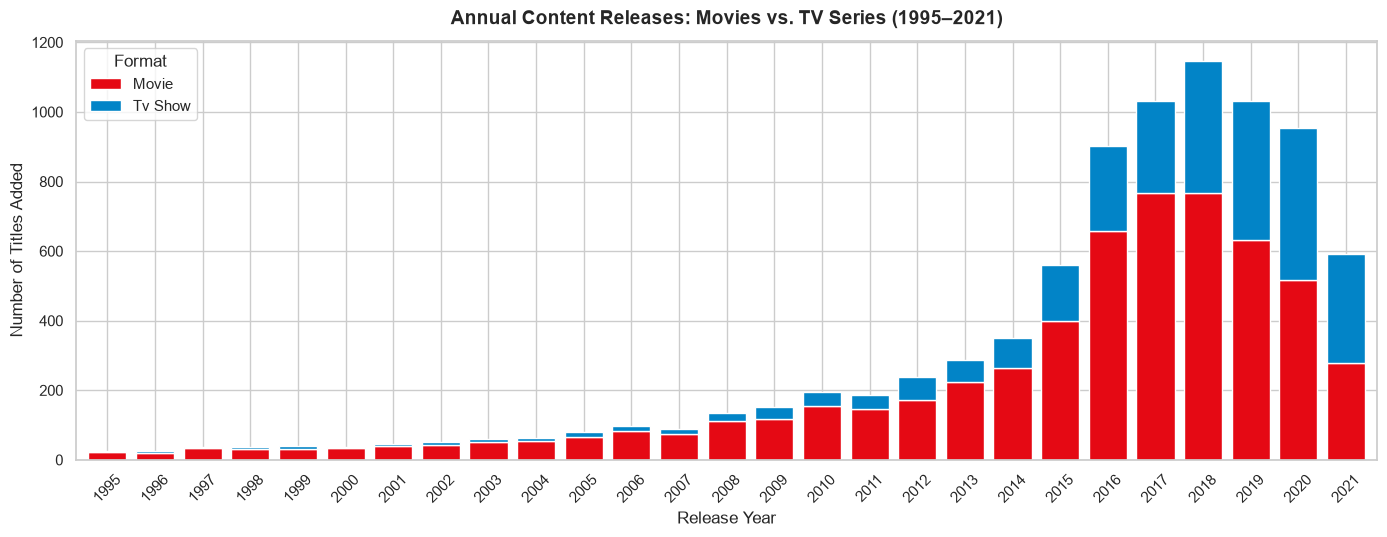

In [5]:
yearly_data = df[df['release_year'] >= 1995].groupby(['release_year', 'type']).size().unstack(fill_value=0)

plt.figure(figsize=(14, 5.5))
yearly_data.plot(kind='bar', stacked=True, color=['#E50914', '#0284C7'], ax=plt.gca(), width=0.8)
plt.title("Annual Content Releases: Movies vs. TV Series (1995–2021)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Release Year")
plt.ylabel("Number of Titles Added")
plt.xticks(rotation=45)
plt.legend(title="Format", loc='upper left')
plt.tight_layout()
plt.show()

*Insight:* Annual releases accelerated dramatically between 2015 and 2019 during the peak of streaming market expansion. Notice how episodic TV shows expanded from ~15% of annual releases pre-2015 to over 34% by 2020.


C:\Users\justk\AppData\Local\Temp\ipykernel_9960\178632366.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genres.values, y=top_genres.index, palette="flare")


findfont: Failed to find font weight 500, now using 400.


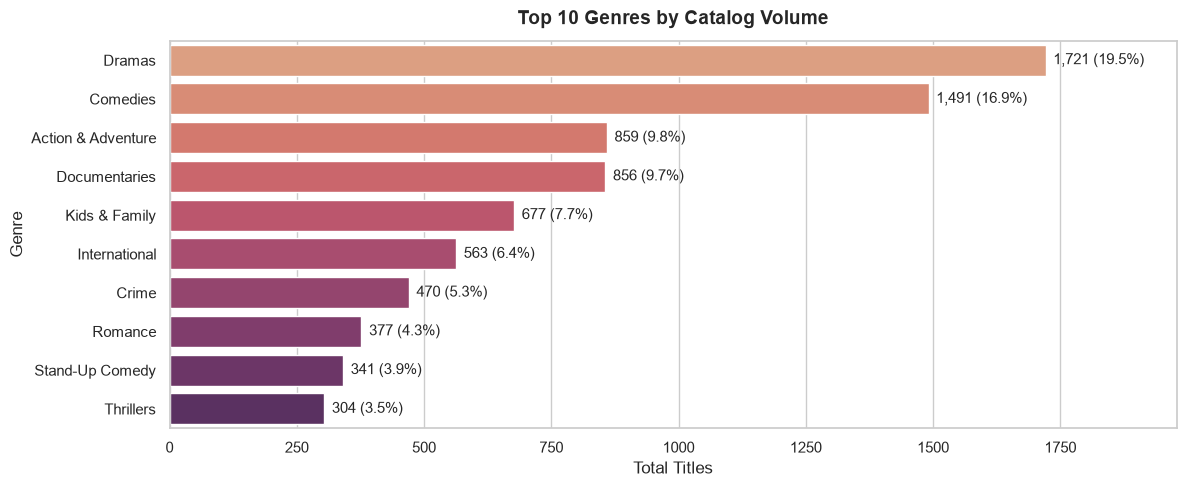

In [6]:
top_genres = df['genre'].value_counts().head(10)

plt.figure(figsize=(12, 5))
sns.barplot(x=top_genres.values, y=top_genres.index, palette="flare")
plt.title("Top 10 Genres by Catalog Volume", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Total Titles")
plt.ylabel("Genre")
for i, v in enumerate(top_genres.values):
    plt.text(v + 15, i, f"{v:,} ({v/len(df)*100:.1f}%)", va='center', fontweight='500')
plt.xlim(0, max(top_genres.values) * 1.15)
plt.tight_layout()
plt.show()

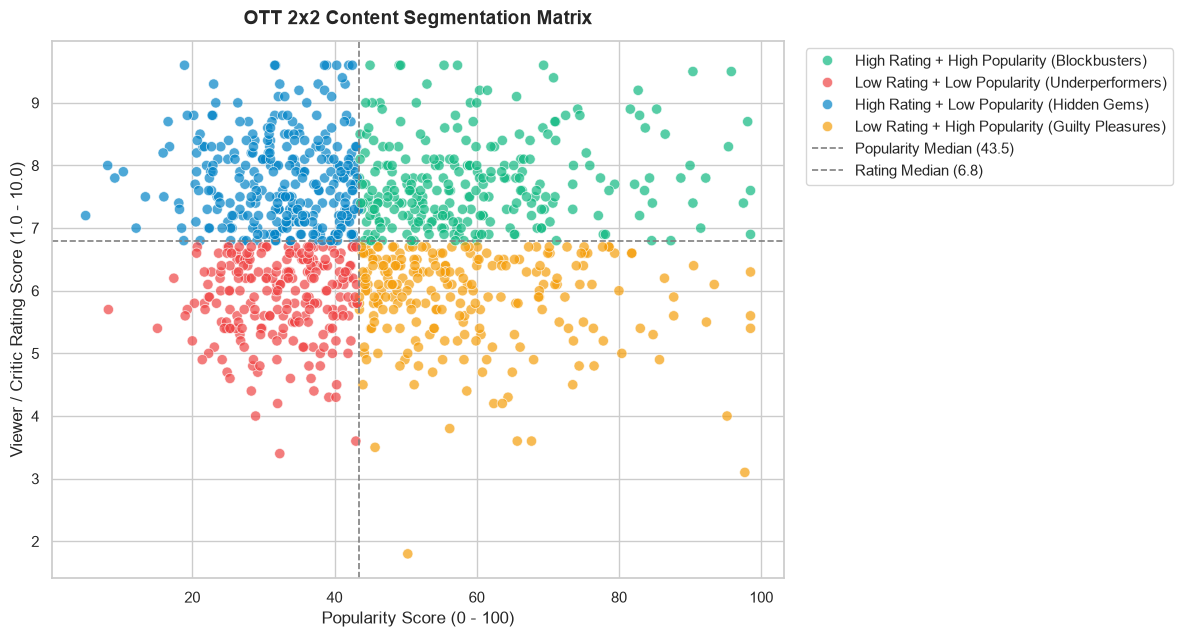

In [7]:
plt.figure(figsize=(12, 6.5))
sample_df = df.dropna(subset=['rating_score', 'popularity']).sample(1000, random_state=42)

palette_dict = {
    "High Rating + High Popularity (Blockbusters)": "#10B981",
    "High Rating + Low Popularity (Hidden Gems)": "#0284C7",
    "Low Rating + High Popularity (Guilty Pleasures)": "#F59E0B",
    "Low Rating + Low Popularity (Underperformers)": "#EF4444"
}

sns.scatterplot(
    data=sample_df,
    x='popularity',
    y='rating_score',
    hue='content_segment',
    palette=palette_dict,
    alpha=0.7,
    s=55
)
plt.axvline(pop_med, color='gray', linestyle='--', linewidth=1.2, label=f'Popularity Median ({pop_med})')
plt.axhline(rating_med, color='gray', linestyle='--', linewidth=1.2, label=f'Rating Median ({rating_med})')
plt.title("OTT 2x2 Content Segmentation Matrix", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Popularity Score (0 - 100)")
plt.ylabel("Viewer / Critic Rating Score (1.0 - 10.0)")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 5. SQL Analysis with DuckDB
As an analytics engineer, I prefer running SQL queries to produce reliable summary aggregates. Let's register our cleaned dataframe with DuckDB.


In [8]:
con = duckdb.connect()
con.register('ott_titles', df)

q1 = """
SELECT 
    COUNT(*) AS total_titles,
    SUM(CASE WHEN type = 'Movie' THEN 1 ELSE 0 END) AS movies,
    ROUND(100.0 * SUM(CASE WHEN type = 'Movie' THEN 1 ELSE 0 END) / COUNT(*), 1) AS movie_pct,
    SUM(CASE WHEN type = 'Tv Show' THEN 1 ELSE 0 END) AS tv_shows,
    ROUND(100.0 * SUM(CASE WHEN type = 'Tv Show' THEN 1 ELSE 0 END) / COUNT(*), 1) AS tv_pct,
    ROUND(AVG(rating_score), 2) AS avg_rating,
    ROUND(AVG(popularity), 2) AS avg_popularity
FROM ott_titles;
"""
display(con.execute(q1).fetchdf())

,total_titles,movies,movie_pct,tv_shows,tv_pct,avg_rating,avg_popularity
0,8806,6130.0,69.6,2676.0,30.4,6.83,45.87


In [9]:
q2 = """
SELECT 
    content_segment,
    COUNT(*) AS titles,
    ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM ott_titles), 1) AS catalog_pct,
    ROUND(AVG(rating_score), 2) AS avg_rating,
    ROUND(AVG(popularity), 2) AS avg_popularity
FROM ott_titles
GROUP BY content_segment
ORDER BY titles DESC;
"""
display(con.execute(q2).fetchdf())

,content_segment,titles,catalog_pct,avg_rating,avg_popularity
0,High Rating + Low Popularity (Hidden Gems),2196,24.9,7.75,32.39
1,High Rating + High Popularity (Blockbusters),2091,23.7,7.73,59.27
2,Low Rating + High Popularity (Guilty Pleasures),2008,22.8,5.86,59.30
3,Low Rating + Low Popularity (Underperformers),1887,21.4,5.82,32.48
4,Unsegmented (Missing Metric),624,7.1,6.83,45.62


In [10]:
q3 = """
SELECT 
    title, 
    type, 
    release_year, 
    genre, 
    language, 
    rating_score, 
    popularity
FROM ott_titles
WHERE content_segment LIKE '%Hidden Gems%'
ORDER BY rating_score DESC, popularity ASC
LIMIT 10;
"""
display(con.execute(q3).fetchdf())

,title,type,release_year,genre,language,rating_score,popularity
0,This Is the Life,Movie,2008,Documentaries,English,9.6,16.5
1,American Psycho,Movie,2000,Comedies,English,9.6,17.7
2,My Little Pony Equestria Girls: Forgotten Frie...,Movie,2018,Kids & Family,English,9.6,18.8
3,After the Raid,Movie,2019,Documentaries,English,9.6,18.9
4,Jerry Seinfeld: Comedian,Movie,2002,Documentaries,English,9.6,19.6
5,A Walk to Remember,Movie,2002,Dramas,English,9.6,19.7
6,Mean Streets,Movie,1973,Dramas,English,9.6,22.2
7,Vampire Knight,Tv Show,2008,Anime,Japanese,9.6,22.2
8,Marvel Anime: Wolverine,Tv Show,2011,Anime,English,9.6,22.4
9,Studio 54,Movie,2018,Documentaries,English,9.6,22.5


## 6. Strategic Takeaways & Content Team Recommendations

1. **Leverage the 'Hidden Gems' Segment (24.9% of catalog):**
   - With an average rating of **7.75/10** but low popularity (avg 32.4), these titles represent latent value. Surfacing them on homepage recommendation carousels drives stream time at zero additional acquisition cost.
2. **Audit and Prune 'Underperformers' (21.4% of catalog):**
   - Titles with both low ratings (<6.8) and low popularity (<43.5) represent catalog bloat. The content team should consider letting contracts expire rather than renewing them.
3. **Format Strategy (Movies vs. Series):**
   - Continue expanding the episodic TV series catalog. Series create weekly viewing habits and significantly reduce month-over-month subscriber churn.
4. **International Catalog Efficiency:**
   - Regional production hubs like India, Japan, and South Korea deliver strong audience ratings per dollar spent compared to domestic Hollywood productions.
